In [1]:
import os 
import glob
import comet_ml
import torch
import torchaudio
from src.logger.utils import plot_spectrogram
from omegaconf import OmegaConf
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate
from IPython.display import Audio, display
import matplotlib.pyplot as plt

In [2]:
ROOT = os.getcwd()

with initialize_config_dir(config_dir=os.path.join(ROOT, "src/configs"), version_base=None):
    cfg = compose(config_name="conformer_s")

wav_aug_cfgs = list(cfg.transforms.instance_transforms.train.audio.transforms)
spec_aug_cfgs = list(cfg.transforms.batch_transforms.train.spectrogram._args_)
get_spec = instantiate(cfg.transforms.instance_transforms.inference.get_spectrogram)

print([c._target_.split(".")[-1] for c in wav_aug_cfgs])
print([c._target_.split(".")[-1] for c in spec_aug_cfgs])

['Gain', 'AddColoredNoise', 'BandPassFilter']
['FrequencyMasking', 'TimeMasking']


In [3]:
AUDIO_PATH = sorted(glob.glob(os.path.join(ROOT, "data/datasets/librispeech/dev-clean/**/*.flac"), recursive=True))[0]
wav, sr = torchaudio.load(AUDIO_PATH)
wav = wav[:1]
print(wav.shape)

torch.Size([1, 93680])


/workspace/dla_asr/.venv/lib/python3.12/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
/workspace/dla_asr/.venv/lib/python3.12/site-packages/torchaudio/_backend/ffmpeg.py:88: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for mo

In [4]:
spectrogram = get_spec(wav)
display(Audio(wav[0].numpy(), rate=16000))

In [5]:
augmented = {}
for aug_cfg in wav_aug_cfgs:
    params = OmegaConf.to_container(aug_cfg, resolve=True)
    params["p"] = 1
    name = params["_target_"].split(".")[-1]
    out = instantiate(params)(wav.clone())

    augmented[name] = out
    print(name)
    display(Audio(out[0].numpy(), rate=16000))

/workspace/dla_asr/.venv/lib/python3.12/site-packages/torch_audiomentations/core/transforms_interface.py:76: FutureWarning: Transforms now expect an `output_type` argument that currently defaults to 'tensor', will default to 'dict' in v0.12, and will be removed in v0.13. Make sure to update your code to something like:
  >>> augment = Gain(..., output_type='dict')
  >>> augmented_samples = augment(samples).samples
  warnings.warn(


Gain


AddColoredNoise


/workspace/dla_asr/.venv/lib/python3.12/site-packages/torch_audiomentations/core/transforms_interface.py:76: FutureWarning: Transforms now expect an `output_type` argument that currently defaults to 'tensor', will default to 'dict' in v0.12, and will be removed in v0.13. Make sure to update your code to something like:
  >>> augment = BandPassFilter(..., output_type='dict')
  >>> augmented_samples = augment(samples).samples
  warnings.warn(


BandPassFilter


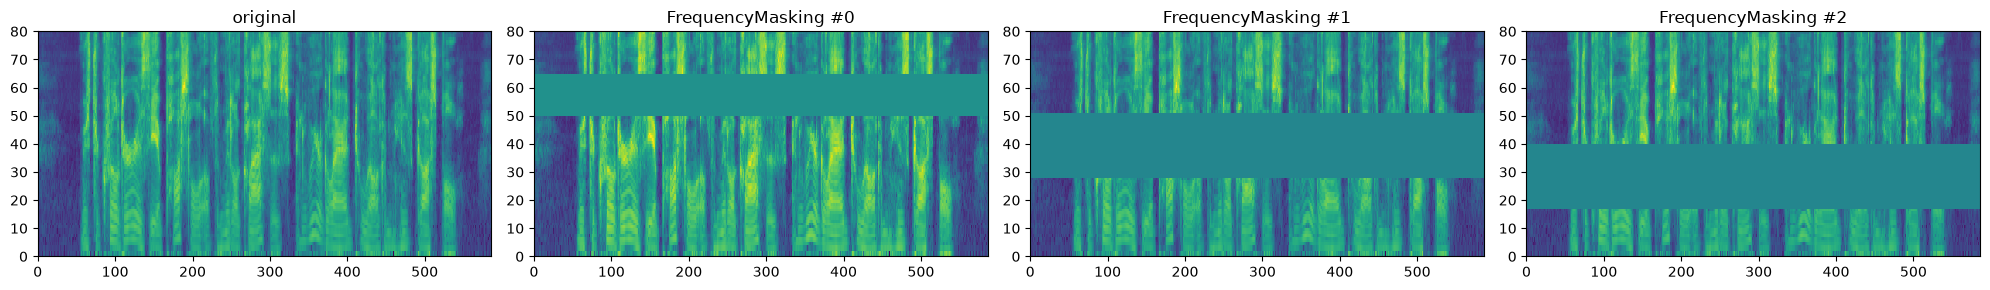

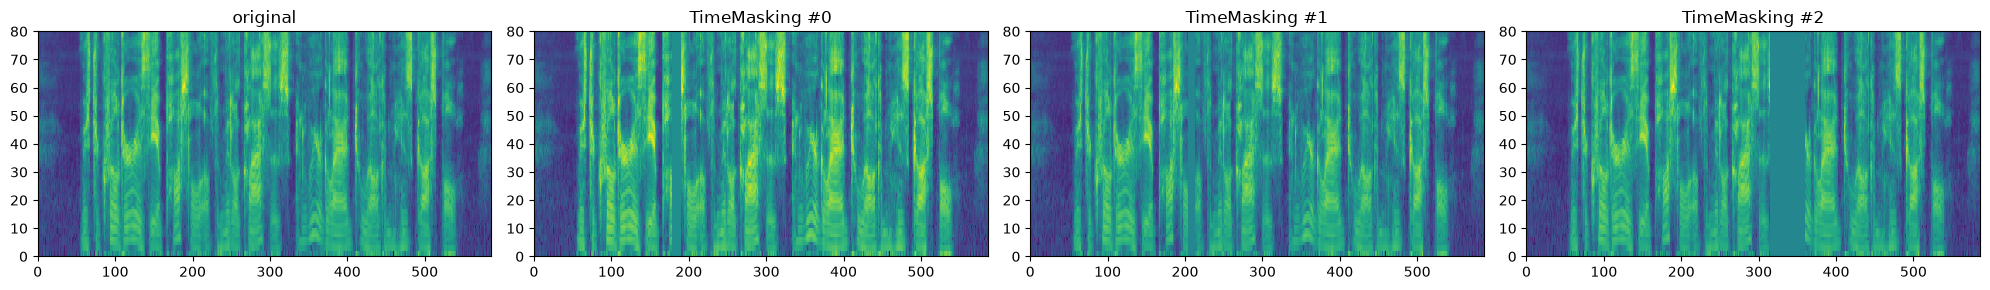

In [6]:
%matplotlib inline
n = 3
spec_augmented = {}
for aug_cfg in spec_aug_cfgs:
    name = aug_cfg._target_.split(".")[-1]
    aug = instantiate(aug_cfg)
    spec_augmented[name] = [aug(spectrogram.clone()) for _ in range(n)]

    fig, axes = plt.subplots(1, n + 1, figsize=(5 * (n + 1), 3))
    axes[0].pcolormesh(spectrogram[0])
    axes[0].set_title("original")
    for i, s in enumerate(spec_augmented[name]):
        axes[i + 1].pcolormesh(s[0])
        axes[i + 1].set_title(f"{name} #{i}")
    plt.tight_layout()
    display(fig)
    plt.close(fig)

In [7]:
ROOT = os.getcwd()

comet_ml.login()
conf = OmegaConf.load("src/configs/writer/cometml.yaml")
exp = comet_ml.Experiment(project_name=conf.project_name, workspace=conf.workspace)
exp.set_name("aug_check")

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.


COMET INFO: Experiment is live on comet.com https://www.comet.com/niki-romanenko/asr-train/e3a6cffa565a4d2a8cb953c792dcab2c



In [8]:
def spec_image(spec, name):
    return plot_spectrogram(spec[0].detach().cpu(), name=name).permute(1, 2, 0).numpy()

def log_wav(name, signal):
    exp.log_audio(signal[0].numpy(), sample_rate=16000, file_name=f"{name}.wav")
    exp.log_image(spec_image(get_spec(signal), name), name=f"{name}_spec")

log_wav("original", wav)
for name, out in augmented.items():
    log_wav(name, out)

for name, examples in spec_augmented.items():
    for i, s in enumerate(examples):
        exp.log_image(spec_image(s, f"{name}_{i}"), name=f"{name}_{i}")

In [9]:
exp.end()

COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : aug_check
COMET INFO:     url                   : https://www.comet.com/niki-romanenko/asr-train/e3a6cffa565a4d2a8cb953c792dcab2c
COMET INFO:   Others:
COMET INFO:     Name : aug_check
COMET INFO:   Uploads:
COMET INFO:     audio                    : 4
COMET INFO:     environment details      : 1
COMET INFO:     filename                 : 1
COMET INFO:     git metadata             : 1
COMET INFO:     git-patch (uncompressed) : 1 (1.75 MB)
COMET INFO:     images                   : 10
COMET INFO:     installed packages       : 1
COMET INFO:     notebook                 : 1
COMET INFO:     os packages              : 1
COMET INFO:     source_code       